# DC4 511 keV Imaging and Residual Analysis

This notebook runs the complete imaging workflow in one kernel: it combines the weekly observations, prepares the simulated background and detector response, reconstructs the 511 keV sky, evaluates the fitted source and background expectations, and calculates residual diagnostics directly from the in-memory histograms. No intermediate residual-product file is required.

In [1]:
%load_ext autoreload
%autoreload 2

## 1. Environment and imports

The following cells locate the workflow directory, import the imaging and residual-analysis interfaces, and load the centralized input paths.

In [2]:
# Locate the workflow root so local modules can be imported.
from pathlib import Path
import sys

working_dir = Path.cwd()
repo_root = (
    working_dir.parent 
    if working_dir.name == "notebooks"
    else working_dir
)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [3]:
import numpy as np
import cosipy as cp
import matplotlib.pyplot as plt

from cosipy.image_deconvolution import DataIF_COSI_DC2, ImageDeconvolution
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals
import healpy as hp
from histpy import Histogram
import astropy.units as u
from astromodels import DiracDelta
from IPython.display import display
from src.convoluton_imager import plot_reconstructed_image

%matplotlib inline

### 1.1 Input paths and DATAIO configuration

All input locations come from `src.path_to_files`. Inspecting the key paths here makes missing or misplaced products fail early, before the expensive reconstruction starts.

In [4]:
# Input products: add all paths used by this analysis. See `workflow/src/path_to_files.py`.
from src import path_to_files as paths

In [5]:
# Display the main response and weekly-output locations.
print(paths.data_ext_response511_path)
print(paths.data_dir_out)

/Users/maura/Documents/COSI/data-challenge-4/workflow/data/inputs/extended_source_response_511_merged.h5
/Users/maura/Documents/COSI/data-challenge-4/workflow/data/outputs


In [6]:
# Select the DATAIO configuration for the 511 keV event files.
yaml_conf = paths.config_511_path
yaml_conf

PosixPath('/Users/maura/Documents/COSI/data-challenge-4/workflow/data/config/dataio_511.yaml')

## 2. Observed 511 keV data

Each weekly product contains a time-resolved event histogram. The full weekly `(Time, Em, Phi, PsiChi)` histograms are added first to retain `Observed_temporal_counts` ($D_{t,i}$). Projecting out time then gives `observed_atemporal_counts` ($D_i$), used by the imaging fit through the existing `observed_event_hist` name.

In [7]:
# Load every weekly binned observation.
analysis511 = {}

for week in paths.weekly_paths:
    output_prefix = paths.data_dir_out / f"dc4_week_{week}_511_binned"
    output_path = output_prefix.with_suffix(".hdf5")

    analysis511[week] = cp.BinnedData(yaml_conf)
    analysis511[week].load_binned_data_from_hdf5(
        binned_data=str(output_path)
    )
    analysis511[week].get_binning_info()

In [8]:
# Copy the first full histogram to preserve the original weekly data.
observed_weeks = list(paths.weekly_paths)
Observed_temporal_counts = analysis511[observed_weeks[0]].binned_data.copy()

# Add counts only when all time and CDS bins match exactly.
for week in observed_weeks[1:]:
    week_hist = analysis511[week].binned_data
    if week_hist.axes != Observed_temporal_counts.axes:
        raise ValueError(f"Week {week} has incompatible time or CDS bins.")
    # Use out-of-place addition to preserve sparse histogram contents.
    Observed_temporal_counts = Observed_temporal_counts + week_hist

# Sum over time only after combining the full temporal histograms.
observed_atemporal_counts = (
    Observed_temporal_counts
    .project("Em", "Phi", "PsiChi")
    .to_dense(copy=False)
)

# Keep the imaging workflow connected to the atemporal counts.
observed_event_hist = observed_atemporal_counts

print("Observed temporal axes:", Observed_temporal_counts.axes.labels)
print("Observed temporal shape:", Observed_temporal_counts.shape)
print("Observed axes:", observed_event_hist.axes.labels)
print("Observed shape:", observed_event_hist.shape)
print("Observed total counts:", observed_event_hist.contents.sum())

Observed temporal axes: ['Time' 'Em' 'Phi' 'PsiChi']
Observed temporal shape: (2217, 1, 60, 3072)
Observed axes: ['Em' 'Phi' 'PsiChi']
Observed shape: (1, 60, 3072)
Observed total counts: 1576953.0


## 3. Simulated background

The background-only simulation is projected onto the same CDS axes as the observation. Its normalization remains part of the image-deconvolution result.

In [9]:
simulated_background = cp.BinnedData(paths.config_511_path)
simulated_background.load_binned_data_from_hdf5(
    binned_data=str(paths.simulated_background_511_binned_path)
)
simulated_background.get_binning_info()

simulated_background_hist = (
    simulated_background.binned_data
)

In [10]:
# Remove any auxiliary axes while retaining the CDS coordinates.
simulated_bg_counts_all = (
    simulated_background_hist
    .project( "Em", "Phi", "PsiChi")
    .to_dense(copy=False)
)

print("Background axes:", simulated_bg_counts_all.axes.labels)
print("Background shape:", simulated_bg_counts_all.shape)

Background axes: ['Em' 'Phi' 'PsiChi']
Background shape: (1, 60, 3072)


## 4. Imaging response and data interface

The precomputed Galactic response and the observed/background histograms are combined in the COSI image-deconvolution data interface. Matching axes and shapes are checked before fitting.

In [11]:
# Load the precomputed extended-source response.
response_511 = Histogram.open(
    str(paths.data_ext_response511_path)
)

In [12]:
# Verify that observed and background counts use identical CDS bins.
if observed_event_hist.axes != simulated_bg_counts_all.axes:
    raise ValueError("Observed and background histograms have incompatible axes.")

if observed_event_hist.shape != simulated_bg_counts_all.shape:
    raise ValueError("Observed and background histograms have incompatible shapes.")

data_interface = DataIF_COSI_DC2.load(
    name="511keV",
    event_binned_data=observed_event_hist,
    dict_bkg_binned_data={"background": simulated_bg_counts_all},
    rsp=response_511,
    coordsys_conv_matrix=None,
)

In [13]:
# Select the image-deconvolution configuration.
yml_file = paths.config_deconvo_path

In [14]:
# Configure the reconstruction with the simulated-background dataset.
image_deconvolution = ImageDeconvolution()

# Register the prepared data interface.
image_deconvolution.set_dataset([data_interface])
# Load the reconstruction parameters.
image_deconvolution.read_parameterfile(yml_file)

## 5. Image deconvolution

This is the computational fit. The final iteration contains both the reconstructed sky image and the fitted background normalization required to evaluate the expected CDS counts.

In [15]:
image_deconvolution.initialize()
image_deconvolution.run_deconvolution()
image_deconvolution.results

  0%|          | 0/15 [00:00<?, ?it/s]

[{'iteration': 1,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x126eb1550>,
  'background_normalization': {'background': 1.0961076123758495},
  'log-likelihood': [2266291.1040600436],
  'accel_factor': 1.0},
 {'iteration': 2,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x12871ec50>,
  'background_normalization': {'background': 1.0952079248005853},
  'log-likelihood': [2267105.066573919],
  'accel_factor': 10.0},
 {'iteration': 3,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x1285d19d0>,
  'background_normalization': {'background': 1.0863005902917515},
  'log-likelihood': [2268141.8285720265],
  'accel_factor': 10.0},
 {'iteration': 4,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x1287a0a50>,
  'background_normalization': {'background': 1.0777807213964938},
  'log-likelihood': [2269398.1521391096],
  'accel_factor': 10.0},
 {'iteration': 5,
  'model': <

## 7. Evaluate the fitted CDS expectation

The final reconstruction provides the fitted sky image and background normalization. Folding these fitted quantities through the same data interface produces the source, background, and total expected counts in exactly the observed `(Em, Phi, PsiChi)` bins.

In [16]:
# Read the fitted quantities from the final reconstruction iteration.
final_result = image_deconvolution.results[-1]
fitted_image = final_result["model"]
fitted_background_norm = final_result["background_normalization"]

# Fold the fitted sky and background models into the observed CDS bins.
source_expectation = data_interface.calc_source_expectation(fitted_image)
background_expectation = data_interface.calc_bkg_expectation(
    fitted_background_norm
)
total_expectation = data_interface.calc_expectation(
    fitted_image,
    fitted_background_norm,
)

### 7.1 Validate the observed and expected products

Residuals are meaningful only when observed and expected counts share identical bins. The total expectation must also equal the sum of its fitted source and background components.

In [17]:
# Require identical axes and shapes before comparing the histograms.
if observed_event_hist.axes != total_expectation.axes:
    raise ValueError("Observed and expected histograms have incompatible axes.")

if observed_event_hist.shape != total_expectation.shape:
    raise ValueError("Observed and expected histograms have incompatible shapes.")

component_sum = (
    source_expectation.contents + background_expectation.contents
)
if not np.allclose(total_expectation.contents, component_sum):
    raise ValueError("Total expectation does not match its component sum.")

print("Observed total:", observed_event_hist.contents.sum())
print("Source expectation total:", source_expectation.contents.sum())
print("Background expectation total:", background_expectation.contents.sum())
print("Total expectation:", total_expectation.contents.sum())
print("Background normalization:", fitted_background_norm)

Observed total: 1576953.0
Source expectation total: 193601.10441810387
Background expectation total: 1380440.5071258782
Total expectation: 1574041.6115439823
Background normalization: {'background': 1.003967684829928}


## 8. Residual analysis from in-memory histograms

`ResidualAnalysis` receives the integrated observation and the fitted total expectation directly. Unlike the file-based tutorial, this workflow does not call `Histogram.open()` because both histograms were produced in the current kernel.

In [18]:
# Associate the in-memory histograms explicitly with their analysis roles.
residual_analysis = ResidualAnalysis(
    observed=observed_event_hist,
    expected=total_expectation,
)

# Calculate one projected residual for direct numerical inspection.
phi_raw_residual = residual_analysis.residual_function(
    "Phi_projection",
    residual_type="raw",
)

print("Residual axes:", phi_raw_residual.axes.labels)
print("Residual shape:", phi_raw_residual.shape)
print("Mask report:", residual_analysis.mask_report)

Observed data have no time information; using atemporal residual analysis.
Residual axes: ['Phi']
Residual shape: (60,)
Mask report: {'total_bins': 184320, 'valid_bins': np.int64(184320), 'excluded_bins': np.int64(0), 'observed_counts_excluded': np.float64(0.0), 'expected_floor': None, 'minimum_expected': <Quantity 1.e-12>, 'minimum_retained_expected': <Quantity 1.e-12>}


### 8.1 Projected residual diagnostics

The plotting interface reuses the same analysis object. Raw residuals show count differences, while Pearson residuals scale those differences by the square root of the fitted expectation.

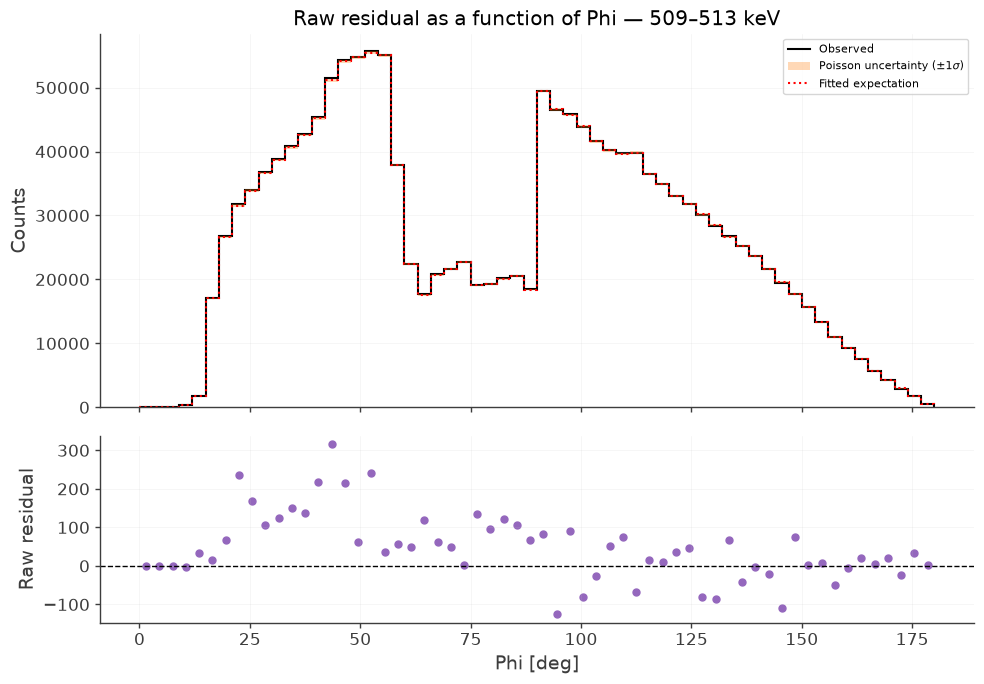


WARNING UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



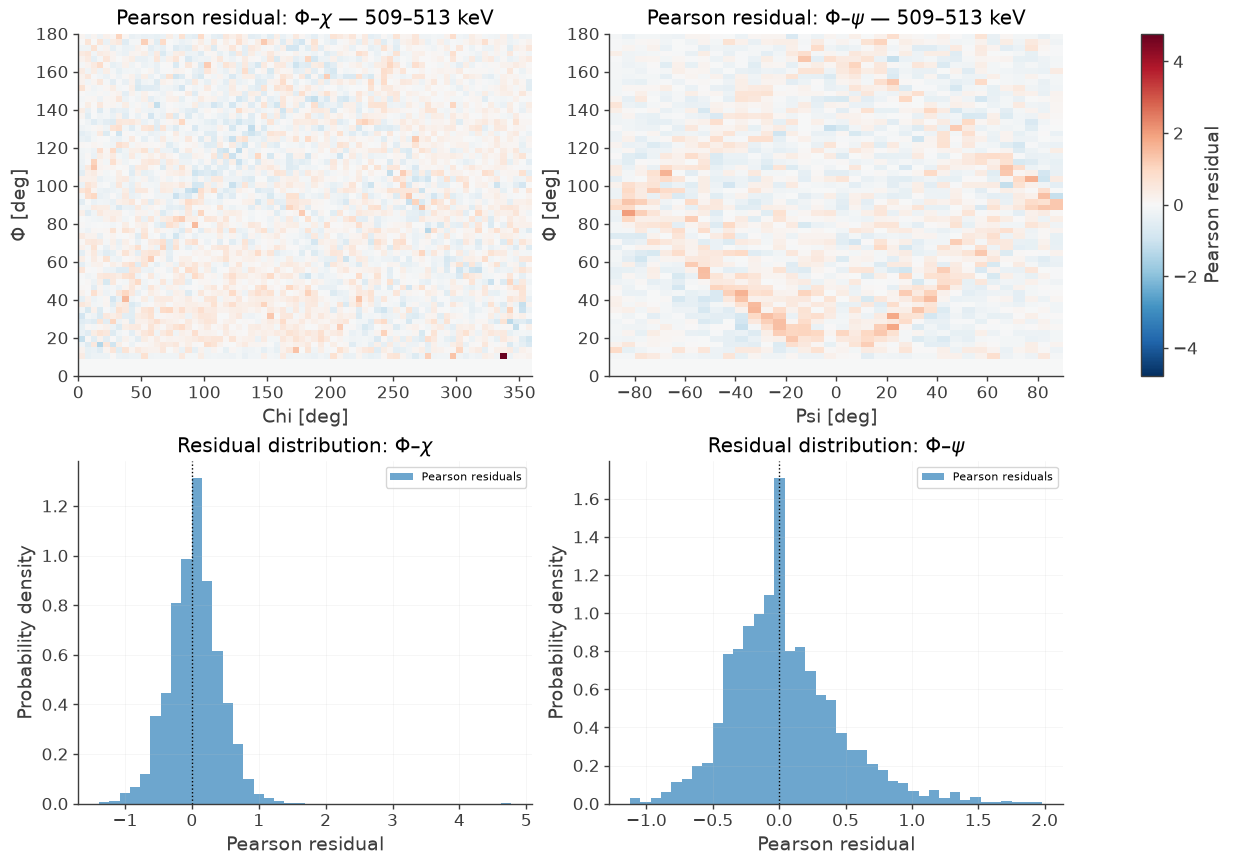

,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,184320,0.006158,-0.079596,0.445315,0.445357,-1.626413,17.35212,0.381402,0.212674,36558.590854,25525.814956


In [19]:
# Configure the plotting interface without Monte Carlo references.
residual_plotter = PlottingResiduals(residual_analysis)

# Compare observed and expected counts along the Phi projection.
phi_raw_figure = residual_plotter.plot(
    "Phi_projection",
    residual_type="raw",
)

# Inspect the angular residual maps in expectation-scaled units.
angular_pearson_figure = residual_plotter.plot(
    "Phi_Chi_projection",
    residual_type="pearson",
    show_gaussian_reference=False,
)

display(residual_analysis.statistics_table("pearson"))

# 9. Physical time-resolved prediction: one-interval prototype

Use the fitted sky image and background normalization from section 7 to calculate a provisional physical expectation for a selected time bin. The signal uses the detector response and spacecraft orientation for that interval; the background uses the time-binned DC4 background simulation.

The response settings must still be checked against the precomputed response used in the fit. The simulated background may share events with the observed DC4 data, so this plot is a diagnostic, not an independent goodness-of-fit test. The fitted sky is assumed constant.


In [20]:
# Import the temporal analysis class and time utilities.
from time import perf_counter
from astropy.time import Time
from src.time_resolved_residuals_v1 import TimeResolvedResidualAnalysis

# Prepare the temporal class using the observed counts and integrated model axes.
physical_temporal_analysis = TimeResolvedResidualAnalysis(
    observed=Observed_temporal_counts,
    integrated_expected=total_expectation,
)
number_of_time_bins = physical_temporal_analysis.observed_hist.axes["Time"].nbins

# Select one interval for the physical prediction and observed comparison.
time_bin_index = 13
if not 0 <= time_bin_index < number_of_time_bins:
    raise IndexError("The selected time bin is outside the available range.")
selected_observed_hist = Histogram(
    list(physical_temporal_analysis.observed_hist.axes)[1:],
    contents=physical_temporal_analysis.observed_hist.contents[time_bin_index].copy(),
    copy_contents=False,
)
print("Available time bins:", number_of_time_bins)
print("Selected time-bin index:", time_bin_index)


Available time bins: 2217
Selected time-bin index: 13


In [ ]:
orientation = cp.SpacecraftHistory.open(paths.data_ori_path)

# Include Earth occultation provisionally; the fit response settings require verification.
physical_earth_occ = True
physical_start_time = perf_counter()

# Fold the fitted sky and scale the simulated background for the selected interval.
with cp.response.FullDetectorResponse.open(paths.data_response511_path) as detector_response:
    physical_products = physical_temporal_analysis.build_physical_time_bin(
        time_bin_index=time_bin_index,
        fitted_image=fitted_image,
        detector_response=detector_response,
        orientation=orientation,
        temporal_background=simulated_background_hist,
        background_normalization=fitted_background_norm["background"],
        earth_occ=physical_earth_occ,
    )

# Record the selected interval and report the expected-count contributions.
physical_time_bin_index = time_bin_index
physical_elapsed = perf_counter() - physical_start_time
print("Selected time-bin index:", time_bin_index)
print("Calculation time (seconds):", physical_elapsed)
print("Observed total:", selected_observed_hist.contents.sum())
print("Physical source total:", physical_products["source"].contents.sum())
print("Physical simulated-background total:", physical_products["background"].contents.sum())
print("Physical total:", physical_products["total"].contents.sum())

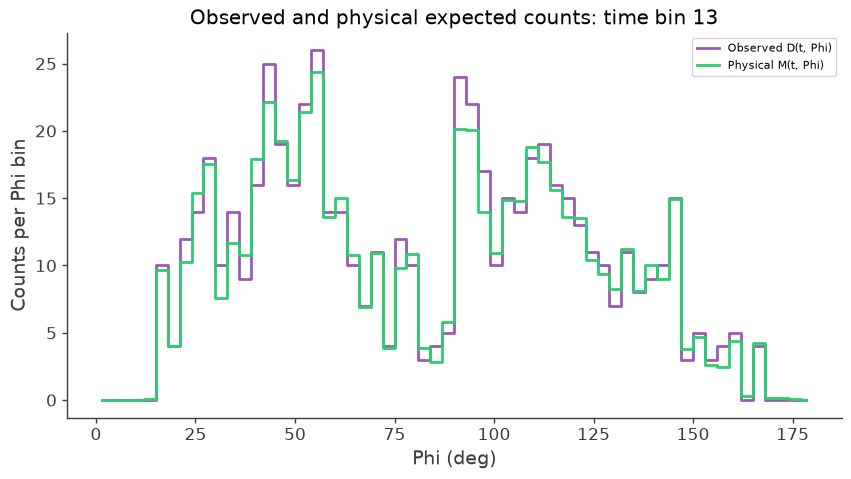

In [ ]:
# Project the observed counts and physical expectation onto the same Phi bins.
physical_observed_phi = selected_observed_hist.project("Phi")
physical_expected_phi = physical_products["total"].project("Phi")
phi_centers = physical_observed_phi.axes["Phi"].centers.to_value(u.deg)

# Compare the observed and physical expected counts for the selected interval.
fig, ax = plt.subplots(figsize=(10, 5))
ax.step(phi_centers, physical_observed_phi.contents, where="mid", label="Observed D(t, Phi)")
ax.step(phi_centers, physical_expected_phi.contents, where="mid", label="Physical M(t, Phi)")
ax.set_xlabel("Phi (deg)")
ax.set_ylabel("Counts per Phi bin")
ax.set_title(f"Observed and physical expected counts: time bin {time_bin_index}")
ax.legend()
plt.show()

### 9.1 Compare five consecutive time bins

The following cells reuse the physical prediction just calculated for the selected bin and calculate the next four bins. Rerun the setup and single-bin calculation if the selected bin changes. Both maps use the same count scale. This remains a provisional diagnostic using the simulated background.


In [ ]:
# Compare the selected interval with the next four consecutive intervals.
first_time_bin = time_bin_index
number_of_comparison_bins = 5
if physical_time_bin_index != first_time_bin:
    raise ValueError("Rerun the selected-bin cells before comparing time bins.")
if first_time_bin + number_of_comparison_bins > number_of_time_bins:
    raise ValueError("Select a time bin with at least four following bins.")

# Reuse the first physical prediction already calculated above.
comparison_observed_phi = []
comparison_expected_phi = []
comparison_start = perf_counter()
with cp.response.FullDetectorResponse.open(paths.data_response511_path) as detector_response:
    for bin_index in range(first_time_bin, first_time_bin + number_of_comparison_bins):
        if bin_index == first_time_bin:
            bin_products = physical_products
        else:
            print(f"Calculating time bin {bin_index}...")
            bin_products = physical_temporal_analysis.build_physical_time_bin(
                time_bin_index=bin_index,
                fitted_image=fitted_image,
                detector_response=detector_response,
                orientation=orientation,
                temporal_background=simulated_background_hist,
                background_normalization=fitted_background_norm["background"],
                earth_occ=physical_earth_occ,
            )

        # Sum the selected observed counts over Em and PsiChi, keeping Phi.
        observed_values = physical_temporal_analysis.observed_hist.contents[bin_index]
        comparison_observed_phi.append(np.asarray(observed_values).sum(axis=(0, 2)))
        comparison_expected_phi.append(bin_products["total"].project("Phi").contents)

comparison_observed_phi = np.asarray(comparison_observed_phi)
comparison_expected_phi = np.asarray(comparison_expected_phi)
print("Comparison time bins:", first_time_bin, "to", first_time_bin + number_of_comparison_bins - 1)
print("Additional calculation time (seconds):", perf_counter() - comparison_start)

Calculating time bin 14...
Calculating time bin 15...
Calculating time bin 16...
Calculating time bin 17...
Comparison time bins: 13 to 17
Additional calculation time (seconds): 425.00913545799995


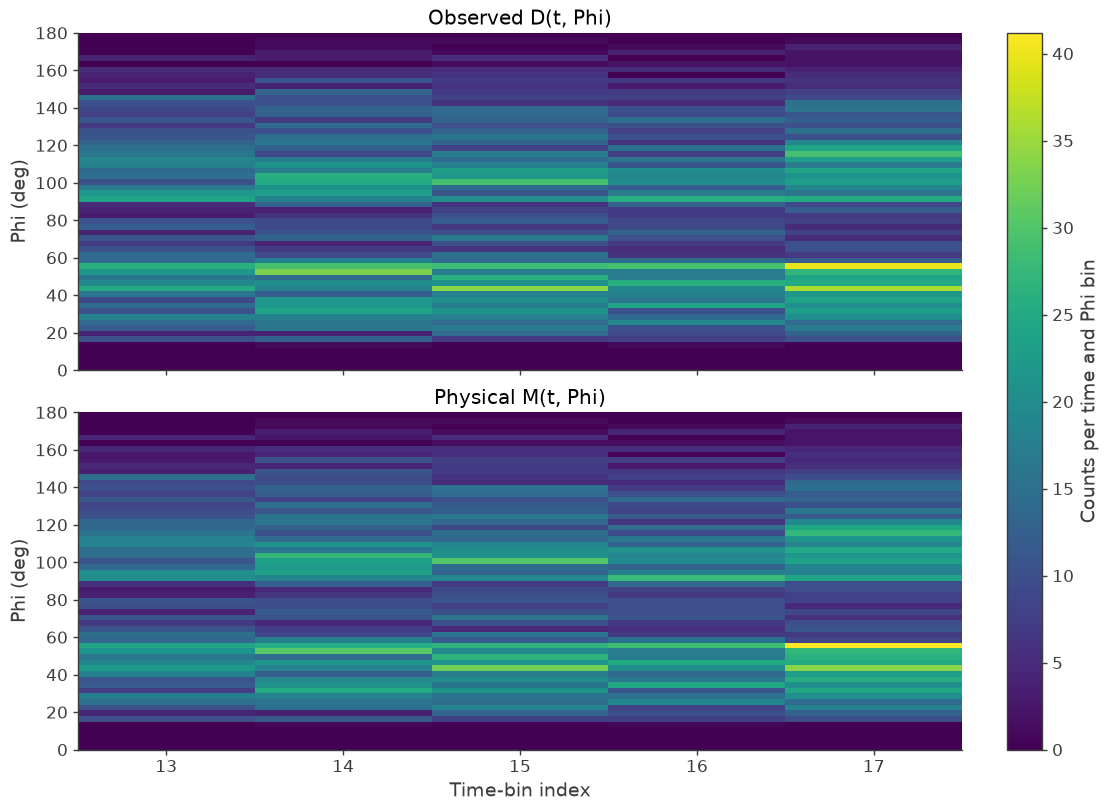

In [ ]:
# Use the same color scale to compare observed and physical counts directly.
phi_edges = physical_observed_phi.axes["Phi"].edges.to_value(u.deg)
time_bin_edges = np.arange(first_time_bin, first_time_bin + number_of_comparison_bins + 1) - 0.5
shared_max = max(comparison_observed_phi.max(), comparison_expected_phi.max())
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, sharey=True, layout="constrained")

# Show the observed and expected Phi distributions in separate panels.
for ax, values, title in zip(
    axes,
    (comparison_observed_phi, comparison_expected_phi),
    ("Observed D(t, Phi)", "Physical M(t, Phi)"),
):
    image = ax.pcolormesh(time_bin_edges, phi_edges, values.T, vmin=0, vmax=shared_max, shading="flat")
    ax.set_title(title)
    ax.set_ylabel("Phi (deg)")

axes[-1].set_xlabel("Time-bin index")
axes[-1].set_xticks(np.arange(first_time_bin, first_time_bin + number_of_comparison_bins))
fig.colorbar(image, ax=axes, label="Counts per time and Phi bin")
plt.show()

In [ ]:
# Sum the observed and expected counts over Phi for each time bin.
observed_counts_vs_time = comparison_observed_phi.sum(axis=1)
expected_counts_vs_time = comparison_expected_phi.sum(axis=1)

# Create the indices corresponding to the selected time bins.
time_indices = np.arange(
    first_time_bin,
    first_time_bin + number_of_comparison_bins,
)

# Check that each time bin has one observed and one expected total.
print("Time-bin indices:", time_indices)
print("Observed counts:", observed_counts_vs_time)
print("Expected counts:", expected_counts_vs_time)

Time-bin indices: [13 14 15 16 17]
Observed counts: [597 709 709 612 785]
Expected counts: [580.82842792 695.3778371  703.57115542 616.06257491 795.08837598]


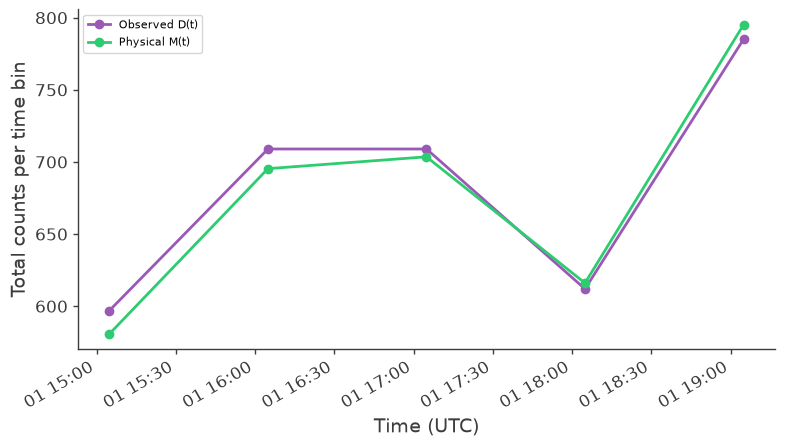

In [ ]:
# Read the physical time boundaries for the five selected bins.
time_edges = physical_temporal_analysis.observed_hist.axes["Time"].edges
selected_edges = time_edges[
    first_time_bin:first_time_bin + number_of_comparison_bins + 1
]

# Convert each interval midpoint from Unix seconds to UTC.
time_midpoints = (selected_edges[:-1] + selected_edges[1:]) / 2
time_utc = Time(time_midpoints.to_value(u.s), format="unix").datetime

# Plot the already calculated total counts against UTC time.
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(time_utc, observed_counts_vs_time, "o-", label="Observed D(t)")
ax.plot(time_utc, expected_counts_vs_time, "o-", label="Physical M(t)")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Total counts per time bin")
ax.legend()
fig.autofmt_xdate()
plt.show()

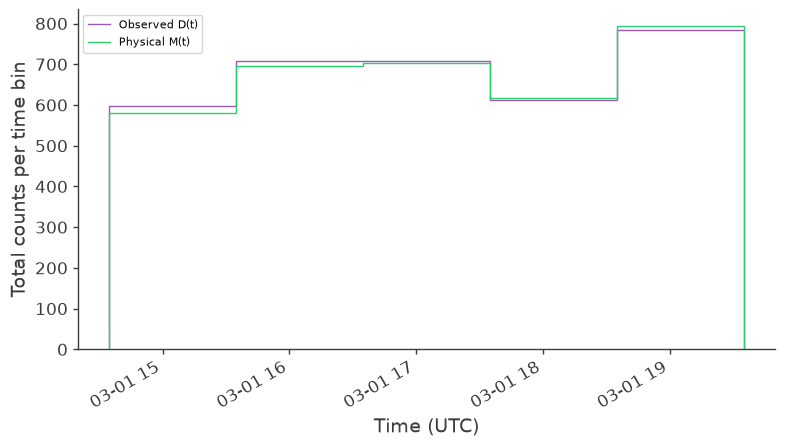

In [ ]:
# Convert the actual time-bin edges from Unix seconds to UTC.
time_edges_utc = Time(
    selected_edges.to_value(u.s),
    format="unix",
).datetime

# Draw one horizontal step across the full width of each time bin.
fig, ax = plt.subplots(figsize=(9, 5))
ax.stairs(
    observed_counts_vs_time,
    time_edges_utc,
    label="Observed D(t)",
)
ax.stairs(
    expected_counts_vs_time,
    time_edges_utc,
    label="Physical M(t)",
)
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Total counts per time bin")
ax.legend()
fig.autofmt_xdate()
plt.show()

In [ ]:
# Use the background normalization obtained from the integrated fit.
background_norm = fitted_background_norm["background"]

# Sum the simulated background separately for each selected interval.
background_totals = []

for bin_index in time_indices:
    # Convert only this interval to a dense array if it is sparse.
    background_bin = simulated_background_hist.contents[bin_index]
    if hasattr(background_bin, "todense"):
        background_bin = background_bin.todense()

    # Apply the fitted normalization to the interval total.
    background_totals.append(background_norm * np.sum(background_bin))

background_counts_vs_time = np.asarray(background_totals)

# Recover the source contribution from the physical total.
source_counts_vs_time = expected_counts_vs_time - background_counts_vs_time

# Display the two contributions for each time bin.
for bin_index, source, background in zip(
    time_indices,
    source_counts_vs_time,
    background_counts_vs_time,
):
    print(
        f"Time bin {bin_index}: "
        f"source = {source:.2f}, "
        f"background = {background:.2f}"
    )

Time bin 13: source = 65.79, background = 515.04
Time bin 14: source = 39.79, background = 655.59
Time bin 15: source = 72.08, background = 631.50
Time bin 16: source = 58.86, background = 557.20
Time bin 17: source = 58.18, background = 736.91


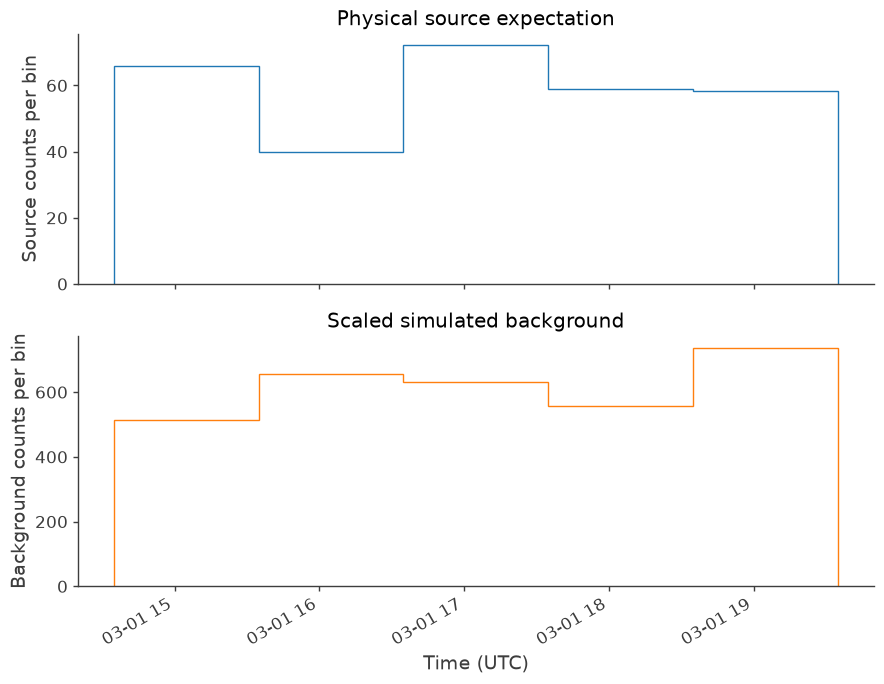

In [ ]:
# Create separate panels because source and background have different scales.
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

# Show the source expectation in each time interval.
axes[0].stairs(source_counts_vs_time, time_edges_utc, color="tab:blue")
axes[0].set_ylabel("Source counts per bin")
axes[0].set_title("Physical source expectation")

# Show the fitted simulated-background contribution in each interval.
axes[1].stairs(background_counts_vs_time, time_edges_utc, color="tab:orange")
axes[1].set_ylabel("Background counts per bin")
axes[1].set_title("Scaled simulated background")
axes[1].set_xlabel("Time (UTC)")

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

In [ ]:
# Reconstruct the integrated background using the fitted normalization.
reconstructed_background = (
    fitted_background_norm["background"]
    * simulated_bg_counts_all.contents
)

# Read the integrated background expectation from the fit.
fitted_background = background_expectation.contents

# Compare the two products in every CDS bin.
background_difference = reconstructed_background - fitted_background

print("Fitted background total:", fitted_background.sum())
print("Reconstructed background total:", reconstructed_background.sum())
print(
    "Maximum absolute difference per CDS bin:",
    np.max(np.abs(background_difference)),
)

Fitted background total: 1380440.5071258782
Reconstructed background total: 1380440.5071258782
Maximum absolute difference per CDS bin: 0.0


In [ ]:
# Sum the original time-binned background over the Time axis.
background_from_time = (
    simulated_background_hist
    .project("Em", "Phi", "PsiChi")
    .to_dense(copy=False)
)

# Apply the background normalization obtained from the integrated fit.
background_from_time_scaled = (
    fitted_background_norm["background"]
    * background_from_time.contents
)

# Compare this temporal sum with the fitted integrated background.
difference = background_from_time_scaled - background_expectation.contents

print("Axes match:", background_from_time.axes == background_expectation.axes)
print("Temporal background total:", background_from_time_scaled.sum())
print("Fitted background total:", background_expectation.contents.sum())
print("Maximum absolute difference per CDS bin:", np.max(np.abs(difference)))

Axes match: True
Temporal background total: 1380440.5071258782
Fitted background total: 1380440.5071258782
Maximum absolute difference per CDS bin: 0.0


In [ ]:
from histpy import Axis, Histogram
from src.time_resolved_residuals_v1 import TimeResolvedResidualAnalysis

# Read the actual boundaries of the previously calculated interval.
original_edges = physical_temporal_analysis.observed_hist.axes["Time"].edges
start = original_edges[time_bin_index]
stop = original_edges[time_bin_index + 1]
midpoint = (start + stop) / 2

# Define two intervals covering exactly the original interval.
half_time_axis = Axis(
    [start.to_value(u.s), midpoint.to_value(u.s), stop.to_value(u.s)],
    label="Time",
    unit=u.s,
)

# Provide the required axes; these zero counts are placeholders, not data.
cds_axes = list(physical_temporal_analysis.observed_hist.axes)[1:]
placeholder_counts = np.zeros((2,) + total_expectation.shape)
placeholder_hist = Histogram(
    [half_time_axis, *cds_axes],
    contents=placeholder_counts,
)

# Prepare the temporal class for the two half-intervals.
half_analysis = TimeResolvedResidualAnalysis(
    observed=placeholder_hist,
    integrated_expected=total_expectation,
)

# Calculate the source expectation for each half using the fitted sky.
half_sources = []

with cp.response.FullDetectorResponse.open(paths.data_response511_path) as detector_response:
    for half_index in range(2):
        print(f"Calculating half-interval {half_index + 1} of 2...")
        half_products = half_analysis.build_physical_time_bin(
            time_bin_index=half_index,
            fitted_image=fitted_image,
            detector_response=detector_response,
            orientation=orientation,
            temporal_background=placeholder_hist,
            background_normalization=0.0,
            earth_occ=physical_earth_occ,
        )
        half_sources.append(half_products["source"].contents.copy())

# Compare the summed halves with the previously calculated full interval.
source_full = physical_products["source"].contents
source_halves = half_sources[0] + half_sources[1]
difference = source_halves - source_full

print("Full-interval source total:", source_full.sum())
print("Sum of half-interval source totals:", source_halves.sum())
print("Difference in total counts:", difference.sum())
print("Maximum absolute difference per CDS bin:", np.max(np.abs(difference)))

Calculating half-interval 1 of 2...
Calculating half-interval 2 of 2...
Full-interval source total: 65.79300560399493
Sum of half-interval source totals: 65.79300683130437
Difference in total counts: 1.2273094343584557e-06
Maximum absolute difference per CDS bin: 3.7217027474157477e-10


In [ ]:
from astropy.time import Time
from time import perf_counter

# Select one sky pixel; this identifies a direction, not an observed event.
sky_pixel = 0

# Use the same full time boundaries as the observed histogram.
full_time_edges = physical_temporal_analysis.observed_hist.axes["Time"].edges
observation_start = Time(full_time_edges[0].to_value(u.s), format="unix")
observation_stop = Time(full_time_edges[-1].to_value(u.s), format="unix")
full_orientation = orientation.select_interval(
    observation_start,
    observation_stop,
)

# Calculate the response for this direction using the DC4 orientation.
comparison_start = perf_counter()

with cp.response.FullDetectorResponse.open(paths.data_response511_path) as detector_response:
    generated_pixel_response = (
        detector_response.get_point_source_response_per_image_pixel(
            sky_pixel,
            full_orientation,
            coordsys="galactic",
            nside_image=fitted_image.axes["lb"].nside,
            earth_occ=physical_earth_occ,
        )
    )

print("Calculation time (seconds):", perf_counter() - comparison_start)

# Check that both responses describe the same energy and CDS bins.
axes_match = generated_pixel_response.axes == response_511.axes[1:]
print("Response axes match:", axes_match)

if not axes_match:
    raise ValueError("The response axes do not match; comparison stopped.")

# Convert the generated response to the units used by the fitted response.
unit_factor = generated_pixel_response.unit.to(response_511.unit)
generated_values = np.asarray(generated_pixel_response.contents) * unit_factor
fitted_response_values = np.asarray(response_511.contents[sky_pixel])

# Compare the response values over all bins for this sky direction.
response_difference = generated_values - fitted_response_values

print("Sky pixel:", sky_pixel)
print("Response unit:", response_511.unit)
print("Generated response total:", generated_values.sum())
print("Fitted response total:", fitted_response_values.sum())
print("Difference in totals:", response_difference.sum())
print(
    "Sum of absolute differences:",
    np.abs(response_difference).sum(),
)

Calculation time (seconds): 0.6009587090011337
Response axes match: True
Sky pixel: 0
Response unit: cm2 s
Generated response total: 36446626.70824015
Fitted response total: 36814136.751779296
Difference in totals: -367510.043539144
Sum of absolute differences: 1307297.315968998


In [ ]:
# Select the three brightest sky pixels in the fitted image.
sky_brightness = np.asarray(fitted_image.contents).sum(axis=1)
brightest_pixels = np.argsort(sky_brightness)[-3:][::-1]

print("Brightest sky pixels:", brightest_pixels)

# Compare the generated and fitted responses for each selected direction.
with cp.response.FullDetectorResponse.open(paths.data_response511_path) as detector_response:
    for sky_pixel in brightest_pixels:
        pixel_response = detector_response.get_point_source_response_per_image_pixel(
            int(sky_pixel),
            full_orientation,
            coordsys="galactic",
            nside_image=fitted_image.axes["lb"].nside,
            earth_occ=physical_earth_occ,
        )

        # Stop if the responses cannot be compared bin by bin.
        if pixel_response.axes != response_511.axes[1:]:
            raise ValueError(f"Response axes do not match for pixel {sky_pixel}.")

        # Express both responses in the same units.
        unit_factor = pixel_response.unit.to(response_511.unit)
        generated = np.asarray(pixel_response.contents) * unit_factor
        fitted = np.asarray(response_511.contents[sky_pixel])

        # Compare the total response and the differences across CDS bins.
        difference = generated - fitted
        fitted_total = fitted.sum()

        print(f"\nSky pixel {sky_pixel}")
        print("Generated response total:", generated.sum())
        print("Fitted response total:", fitted_total)

        if fitted_total > 0:
            print("Relative difference in totals:", difference.sum() / fitted_total)
            print(
                "Relative sum of absolute differences:",
                np.abs(difference).sum() / fitted_total,
            )
        else:
            print("Fitted response total is zero; relative differences are undefined.")

Brightest sky pixels: [1440 1567 1504]

Sky pixel 1440
Generated response total: 35080386.73192844
Fitted response total: 35210867.120499864
Relative difference in totals: -0.0037056851830683797
Relative sum of absolute differences: 0.06569038504790006

Sky pixel 1567
Generated response total: 34345228.23817873
Fitted response total: 34842486.88798786
Relative difference in totals: -0.014271617620399022
Relative sum of absolute differences: 0.06699310356913056

Sky pixel 1504
Generated response total: 37133453.37822604
Fitted response total: 37239991.21303964
Relative difference in totals: -0.0028608447892515204
Relative sum of absolute differences: 0.05901368476343922
